# BizInsight – Business Analysis and Intelligent Recommendations

## Phase 2 – Business Intelligence

The objective of this phase is to transform business data
into meaningful financial insights and actionable
recommendations.

The system will analyze historical business performance,
calculate financial indicators, identify trends and
anomalies, and generate evidence-based recommendations.

The analysis will later be integrated with the existing
machine learning forecasting models.

The main workflow is:

Analyze → Predict → Recommend

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from pathlib import Path

print("Business analysis environment initialized successfully.")

Business analysis environment initialized successfully.


### Load Business Dataset

Locate and load the retail business dataset containing
historical sales, costs, gross profit and transaction data.

This dataset will be used to calculate financial indicators,
identify business performance patterns and generate
actionable recommendations.

In [2]:
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

data_dir = project_dir / "data"

print("Project directory:", project_dir)
print("\nAvailable datasets:")

for file in sorted(data_dir.rglob("*")):
    if file.suffix.lower() in [".csv", ".xlsx", ".xls"]:
        print(file.relative_to(project_dir))

Project directory: /Users/martinagj/Desktop/BizInsight/bizinsight

Available datasets:
data/processed/rossmann_cleaned.csv
data/processed/rossmann_modeling.csv
data/raw/store.csv
data/raw/train.csv
data/recent_retail/retail_inventory_ml_apl.csv
data/recent_retail/retail_sales_ml_apl.csv
data/synthetic_sales.csv


In [3]:
sales_path = (
    data_dir / "recent_retail" / "retail_sales_ml_apl.csv"
)

sales_df = pd.read_csv(sales_path)

print("Sales dataset loaded successfully.")
print("Number of records:", len(sales_df))
print("Number of columns:", len(sales_df.columns))

print("\nAvailable columns:")

for column in sales_df.columns:
    print(column)

Sales dataset loaded successfully.
Number of records: 125751
Number of columns: 17

Available columns:
Transaction Date
Sales Type
Is Return
Reason of Return
Supplier
Product No
Product Description
Product Division
Product Category
Product Subcategory
Product Segment
Store
Sales Channel
Qty Sold
Sales Amount
Cogs
Number of Transactions


In [4]:
sales_df.head(10)

,Transaction Date,Sales Type,Is Return,Reason of Return,Supplier,Product No,Product Description,Product Division,Product Category,Product Subcategory,Product Segment,Store,Sales Channel,Qty Sold,Sales Amount,Cogs,Number of Transactions
0,2025-09-01,Full Price,0,NaN,Vendor 0169,PROD-139867,PROD-100449 SEG-500065 Scholar Footwear Trailb...,Scholar Footwear,Scholar Footwear Trailblazer,Scholar Footwear Trailblazer Equilibrium,SEG-500065 Scholar Footwear Trailblazer Equili...,STR-1006,Channel Alpha,1.0,115.00,52.31,1
1,2025-09-07,Full Price,0,NaN,Vendor 0166,PROD-100449,PROD-100825 SEG-500112 Heritage Footwear Fligh...,Femme Footwear,Femme Footwear Flight Classic,Femme Footwear Flight Classic Varied,SEG-500112 Heritage Footwear Flight Classic Ze...,STR-1198,Channel Alpha,1.0,115.00,58.47,1
2,2025-08-06,Promo,0,NaN,Vendor 0169,PROD-153623,PROD-148813 SEG-511388 Scholar Footwear Trailb...,Scholar Footwear,Scholar Footwear Trailblazer,Scholar Footwear Trailblazer Equilibrium,SEG-511388 Scholar Footwear Trailblazer Equili...,STR-1157,Channel Alpha,1.0,79.99,43.76,1
3,2025-08-31,Full Price,0,NaN,Vendor 0246,PROD-140876,PROD-100419 SEG-500063 Scholar Footwear Boot C...,Scholar Footwear,Scholar Footwear Boot Collection,Scholar Footwear Boot Collection Woodland,SEG-500063 Scholar Footwear Boot Collection Wo...,STR-1234,Channel Alpha,1.0,110.00,50.60,1
4,2026-03-22,Full Price,0,NaN,Vendor 0169,PROD-166113,PROD-149345 SEG-511444 Femme Footwear Trailbla...,Femme Footwear,Femme Footwear Trailblazer,Femme Footwear Trailblazer Equilibrium,SEG-511444 Femme Footwear Trailblazer Equilibrium,STR-1157,Channel Alpha,1.0,160.00,77.95,1
5,2025-08-27,Full Price,0,NaN,Vendor 0169,PROD-123292,PROD-102560 SEG-500349 Scholar Footwear Trailb...,Scholar Footwear,Scholar Footwear Trailblazer,Scholar Footwear Trailblazer Equilibrium,SEG-500349 Scholar Footwear Trailblazer Equili...,STR-1075,Channel Alpha,1.0,115.00,51.57,1
6,2025-11-15,Full Price,0,NaN,Vendor 0010,PROD-149689,PROD-103114 SEG-500427 Scholar Footwear Court ...,Scholar Footwear,Scholar Footwear Court Casual,Scholar Footwear Court Casual Trident,SEG-500427 Scholar Footwear Court Casual Trident,STR-1338,Channel Alpha,1.0,80.00,37.60,1
7,2025-07-27,Promo,0,NaN,Vendor 0134,PROD-152066,PROD-112310 SEG-502364 Scholar Footwear Modern...,Scholar Footwear,Scholar Footwear Modern Legend,Scholar Footwear Modern Legend Summit,SEG-502364 Scholar Footwear Modern Legend Summit,STR-1253,Channel Alpha,1.0,89.99,60.06,1
8,2025-10-25,Full Price,0,NaN,Vendor 0166,PROD-138975,PROD-122131 SEG-504485 Junior Apparel Cozy Tro...,Junior Apparel,Junior Apparel Cozy Trousers,Junior Apparel Cozy Trousers Varied,SEG-504485 Junior Apparel Cozy Trousers Varied,STR-1148,Channel Alpha,1.0,31.50,20.69,1
9,2025-07-03,Full Price,0,NaN,Vendor 0166,PROD-158681,PROD-188033 SEG-520264 Femme Footwear Trailbla...,Femme Footwear,Femme Footwear Trailblazer,Femme Footwear Trailblazer Zephyr,SEG-520264 Femme Footwear Trailblazer Zephyr,STR-1044,Channel Alpha,1.0,90.00,45.04,1


In [5]:
sales_df.head(10)

,Transaction Date,Sales Type,Is Return,Reason of Return,Supplier,Product No,Product Description,Product Division,Product Category,Product Subcategory,Product Segment,Store,Sales Channel,Qty Sold,Sales Amount,Cogs,Number of Transactions
0,2025-09-01,Full Price,0,NaN,Vendor 0169,PROD-139867,PROD-100449 SEG-500065 Scholar Footwear Trailb...,Scholar Footwear,Scholar Footwear Trailblazer,Scholar Footwear Trailblazer Equilibrium,SEG-500065 Scholar Footwear Trailblazer Equili...,STR-1006,Channel Alpha,1.0,115.00,52.31,1
1,2025-09-07,Full Price,0,NaN,Vendor 0166,PROD-100449,PROD-100825 SEG-500112 Heritage Footwear Fligh...,Femme Footwear,Femme Footwear Flight Classic,Femme Footwear Flight Classic Varied,SEG-500112 Heritage Footwear Flight Classic Ze...,STR-1198,Channel Alpha,1.0,115.00,58.47,1
2,2025-08-06,Promo,0,NaN,Vendor 0169,PROD-153623,PROD-148813 SEG-511388 Scholar Footwear Trailb...,Scholar Footwear,Scholar Footwear Trailblazer,Scholar Footwear Trailblazer Equilibrium,SEG-511388 Scholar Footwear Trailblazer Equili...,STR-1157,Channel Alpha,1.0,79.99,43.76,1
3,2025-08-31,Full Price,0,NaN,Vendor 0246,PROD-140876,PROD-100419 SEG-500063 Scholar Footwear Boot C...,Scholar Footwear,Scholar Footwear Boot Collection,Scholar Footwear Boot Collection Woodland,SEG-500063 Scholar Footwear Boot Collection Wo...,STR-1234,Channel Alpha,1.0,110.00,50.60,1
4,2026-03-22,Full Price,0,NaN,Vendor 0169,PROD-166113,PROD-149345 SEG-511444 Femme Footwear Trailbla...,Femme Footwear,Femme Footwear Trailblazer,Femme Footwear Trailblazer Equilibrium,SEG-511444 Femme Footwear Trailblazer Equilibrium,STR-1157,Channel Alpha,1.0,160.00,77.95,1
5,2025-08-27,Full Price,0,NaN,Vendor 0169,PROD-123292,PROD-102560 SEG-500349 Scholar Footwear Trailb...,Scholar Footwear,Scholar Footwear Trailblazer,Scholar Footwear Trailblazer Equilibrium,SEG-500349 Scholar Footwear Trailblazer Equili...,STR-1075,Channel Alpha,1.0,115.00,51.57,1
6,2025-11-15,Full Price,0,NaN,Vendor 0010,PROD-149689,PROD-103114 SEG-500427 Scholar Footwear Court ...,Scholar Footwear,Scholar Footwear Court Casual,Scholar Footwear Court Casual Trident,SEG-500427 Scholar Footwear Court Casual Trident,STR-1338,Channel Alpha,1.0,80.00,37.60,1
7,2025-07-27,Promo,0,NaN,Vendor 0134,PROD-152066,PROD-112310 SEG-502364 Scholar Footwear Modern...,Scholar Footwear,Scholar Footwear Modern Legend,Scholar Footwear Modern Legend Summit,SEG-502364 Scholar Footwear Modern Legend Summit,STR-1253,Channel Alpha,1.0,89.99,60.06,1
8,2025-10-25,Full Price,0,NaN,Vendor 0166,PROD-138975,PROD-122131 SEG-504485 Junior Apparel Cozy Tro...,Junior Apparel,Junior Apparel Cozy Trousers,Junior Apparel Cozy Trousers Varied,SEG-504485 Junior Apparel Cozy Trousers Varied,STR-1148,Channel Alpha,1.0,31.50,20.69,1
9,2025-07-03,Full Price,0,NaN,Vendor 0166,PROD-158681,PROD-188033 SEG-520264 Femme Footwear Trailbla...,Femme Footwear,Femme Footwear Trailblazer,Femme Footwear Trailblazer Zephyr,SEG-520264 Femme Footwear Trailblazer Zephyr,STR-1044,Channel Alpha,1.0,90.00,45.04,1


#### Data Quality and Validation

Inspect the sales dataset for missing values, duplicate
records, incorrect data types and inconsistent values.

Examine sales and return transactions to ensure that
financial indicators and business recommendations
are calculated correctly.

In [6]:
quality_report = pd.DataFrame({
    "Data Type": sales_df.dtypes.astype(str),
    "Missing Values": sales_df.isnull().sum(),
    "Missing Percentage": (
        sales_df.isnull().mean() * 100
    ).round(2),
    "Unique Values": sales_df.nunique()
})

display(quality_report)

print("Duplicate records:", sales_df.duplicated().sum())

,Data Type,Missing Values,Missing Percentage,Unique Values
Transaction Date,str,0,0.0,326
Sales Type,str,0,0.0,5
Is Return,int64,0,0.0,2
Reason of Return,float64,125751,100.0,0
Supplier,str,0,0.0,30
Product No,str,0,0.0,2326
Product Description,str,0,0.0,2313
Product Division,str,0,0.0,3
Product Category,str,0,0.0,27
Product Subcategory,str,0,0.0,51


Duplicate records: 0


In [7]:
print("Sales types:")
print(sales_df["Sales Type"].value_counts())

print("\nReturn distribution:")
print(sales_df["Is Return"].value_counts())

print("\nFinancial and numerical statistics:")

display(
    sales_df[
        [
            "Qty Sold",
            "Sales Amount",
            "Cogs",
            "Number of Transactions"
        ]
    ].describe().round(2)
)

Sales types:
Sales Type
Full Price         93929
Promo              23651
Markdown Tier 1     4384
Markdown Tier 2     2434
Clearance           1353
Name: count, dtype: int64

Return distribution:
Is Return
0    118260
1      7491
Name: count, dtype: int64

Financial and numerical statistics:


,Qty Sold,Sales Amount,Cogs,Number of Transactions
count,125751.00,125751.00,125751.00,125751.00
mean,0.93,83.36,46.50,1.04
std,0.59,83.66,43.60,0.31
min,-3.00,-380.00,-192.28,1.00
25%,1.00,50.00,37.71,1.00
50%,1.00,90.00,50.05,1.00
75%,1.00,115.00,60.72,1.00
max,14.00,2660.00,1345.96,14.00


In [8]:
display(
    sales_df.loc[
        sales_df["Is Return"] == 1,
        [
            "Transaction Date",
            "Is Return",
            "Reason of Return",
            "Qty Sold",
            "Sales Amount",
            "Cogs"
        ]
    ].head(10)
)

,Transaction Date,Is Return,Reason of Return,Qty Sold,Sales Amount,Cogs
39,2026-03-14,1,NaN,-1.0,-165.00,-83.49
47,2025-07-30,1,NaN,-1.0,-69.99,-50.05
68,2026-03-14,1,NaN,-1.0,-60.00,-23.40
115,2025-12-29,1,NaN,-1.0,-63.00,-38.67
151,2025-08-23,1,NaN,-1.0,-120.00,-60.06
153,2025-08-28,1,NaN,-1.0,-110.00,-50.05
162,2026-01-02,1,NaN,-1.0,-90.00,-45.51
168,2025-12-24,1,NaN,-1.0,-112.00,-67.99
190,2025-09-14,1,NaN,-1.0,-110.00,-55.66
200,2025-12-10,1,NaN,-1.0,-81.00,-45.54


#### Data Cleaning and Preparation

Prepare the sales dataset for financial analysis and
business recommendation generation.

Convert transaction dates, standardize column names,
validate return transactions and calculate gross profit.

Preserve negative return values to ensure accurate
net sales and profitability calculations.

In [9]:
business_df = sales_df.copy()

business_df = business_df.rename(columns={
    "Transaction Date": "Date",
    "Sales Type": "SalesType",
    "Is Return": "IsReturn",
    "Product No": "ProductID",
    "Product Description": "ProductName",
    "Product Division": "Division",
    "Product Category": "Category",
    "Product Subcategory": "Subcategory",
    "Product Segment": "Segment",
    "Sales Channel": "SalesChannel",
    "Qty Sold": "QuantitySold",
    "Sales Amount": "Sales",
    "Cogs": "COGS",
    "Number of Transactions": "Transactions"
})

business_df["Date"] = pd.to_datetime(
    business_df["Date"]
)

business_df = business_df.drop(
    columns=["Reason of Return"]
)

business_df = business_df.sort_values(
    ["Date", "Store"]
).reset_index(drop=True)

print("Data preparation completed.")
print("Records:", len(business_df))
print("Columns:", len(business_df.columns))
print("Start date:", business_df["Date"].min())
print("End date:", business_df["Date"].max())

Data preparation completed.
Records: 125751
Columns: 16
Start date: 2025-06-01 00:00:00
End date: 2026-04-24 00:00:00


In [10]:
return_rows = business_df[
    business_df["IsReturn"] == 1
]

purchase_rows = business_df[
    business_df["IsReturn"] == 0
]

financial_columns = ["Sales", "COGS", "QuantitySold"]

print("Returns with unexpected positive values:")

display(
    (return_rows[financial_columns] > 0).sum()
)

print("Purchases with unexpected negative values:")

display(
    (purchase_rows[financial_columns] < 0).sum()
)

Returns with unexpected positive values:


Sales           0
COGS            0
QuantitySold    0
dtype: int64

Purchases with unexpected negative values:


Sales           0
COGS            0
QuantitySold    0
dtype: int64

In [11]:
business_df["GrossProfit"] = (
    business_df["Sales"] - business_df["COGS"]
)

business_df["Year"] = business_df["Date"].dt.year
business_df["Month"] = business_df["Date"].dt.month

business_df["YearMonth"] = (
    business_df["Date"].dt.to_period("M").astype(str)
)

business_df["DayOfWeek"] = (
    business_df["Date"].dt.day_name()
)

display(
    business_df[
        [
            "Date",
            "Store",
            "ProductID",
            "IsReturn",
            "Sales",
            "COGS",
            "GrossProfit"
        ]
    ].head(10)
)

,Date,Store,ProductID,IsReturn,Sales,COGS,GrossProfit
0,2025-06-01,STR-1006,PROD-165157,0,25.20,14.00,11.20
1,2025-06-01,STR-1006,PROD-159699,0,90.00,45.04,44.96
2,2025-06-01,STR-1006,PROD-138262,0,66.00,52.91,13.09
3,2025-06-01,STR-1006,PROD-129495,0,102.00,80.08,21.92
4,2025-06-01,STR-1006,PROD-160874,0,160.00,80.08,79.92
5,2025-06-01,STR-1006,PROD-158684,0,90.00,45.04,44.96
6,2025-06-01,STR-1006,PROD-161865,0,40.00,14.73,25.27
7,2025-06-01,STR-1006,PROD-162192,0,12.00,9.10,2.90
8,2025-06-01,STR-1006,PROD-163280,0,9.99,5.75,4.24
9,2025-06-01,STR-1006,PROD-156824,0,85.00,38.68,46.32


#### Business Financial KPIs

Calculate the key financial and operational performance
indicators from the prepared business dataset.

These indicators provide an overview of business
performance and serve as the foundation for
automated business recommendations.

In [12]:
gross_sales = purchase_rows["Sales"].sum()
total_returns = abs(return_rows["Sales"].sum())

net_sales = business_df["Sales"].sum()
total_cogs = business_df["COGS"].sum()
gross_profit = business_df["GrossProfit"].sum()

gross_margin = (
    gross_profit / net_sales * 100
    if net_sales > 0 else np.nan
)

units_sold = purchase_rows["QuantitySold"].sum()
units_returned = abs(return_rows["QuantitySold"].sum())

return_rate = (
    units_returned / units_sold * 100
    if units_sold > 0 else np.nan
)

business_kpis = pd.DataFrame({
    "Metric": [
        "Gross Sales",
        "Total Returns Value",
        "Net Sales",
        "Net Cost of Goods Sold",
        "Gross Profit",
        "Gross Profit Margin (%)",
        "Units Sold",
        "Units Returned",
        "Net Units Sold",
        "Unit Return Rate (%)",
        "Unique Products",
        "Total Stores",
        "Total Suppliers"
    ],
    "Value": [
        gross_sales,
        total_returns,
        net_sales,
        total_cogs,
        gross_profit,
        gross_margin,
        units_sold,
        units_returned,
        units_sold - units_returned,
        return_rate,
        business_df["ProductID"].nunique(),
        business_df["Store"].nunique(),
        business_df["Supplier"].nunique()
    ]
})

display(business_kpis.round(2))

,Metric,Value
0,Gross Sales,11215681.26
1,Total Returns Value,733571.01
2,Net Sales,10482110.25
3,Net Cost of Goods Sold,5847751.10
4,Gross Profit,4634359.15
5,Gross Profit Margin (%),44.21
6,Units Sold,124542.00
7,Units Returned,7547.00
8,Net Units Sold,116995.00
9,Unit Return Rate (%),6.06


#### Monthly Business Performance Analysis

Analyze monthly sales, product costs, gross profit
and profit margins to identify business trends,
seasonal patterns and changes in financial performance.

These findings will support automated business
recommendations.

In [13]:
monthly_performance = (
    business_df
    .groupby(business_df["Date"].dt.to_period("M"))
    .agg(
        NetSales=("Sales", "sum"),
        COGS=("COGS", "sum"),
        GrossProfit=("GrossProfit", "sum"),
        NetUnitsSold=("QuantitySold", "sum"),
        DaysRecorded=("Date", "nunique")
    )
    .reset_index()
    .rename(columns={"Date": "Month"})
)

monthly_performance["GrossMargin"] = (
    monthly_performance["GrossProfit"]
    / monthly_performance["NetSales"].where(
        monthly_performance["NetSales"] > 0
    ) * 100
)

monthly_performance["CompleteMonth"] = (
    monthly_performance["DaysRecorded"]
    == monthly_performance["Month"].dt.days_in_month
)

monthly_performance["SalesGrowth"] = (
    monthly_performance["NetSales"]
    .pct_change(fill_method=None) * 100
)

monthly_performance["ProfitGrowth"] = (
    monthly_performance["GrossProfit"]
    .pct_change(fill_method=None) * 100
)

comparable_months = (
    monthly_performance["CompleteMonth"]
    & monthly_performance["CompleteMonth"].shift(
        1, fill_value=False
    )
)

monthly_performance.loc[
    ~comparable_months,
    ["SalesGrowth", "ProfitGrowth"]
] = np.nan

display(monthly_performance.round(2))

/var/folders/7d/5cs169vx0mxf0_lp0wfnbrdh0000gn/T/ipykernel_20982/1068620205.py:49: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_performance.round(2))


,Month,NetSales,COGS,GrossProfit,NetUnitsSold,DaysRecorded,GrossMargin,CompleteMonth,SalesGrowth,ProfitGrowth
0,2025-06,706683.44,373718.93,332964.51,7712.0,30,47.12,True,NaN,NaN
1,2025-07,855571.55,462791.45,392780.10,9545.0,31,45.91,True,21.07,17.96
2,2025-08,1535117.21,831526.10,703591.11,17561.0,31,45.83,True,79.43,79.13
3,2025-09,860457.23,487868.96,372588.27,9654.0,30,43.30,True,-43.95,-47.04
4,2025-10,821266.08,469565.59,351700.49,9226.0,31,42.82,True,-4.55,-5.61
5,2025-11,871946.34,483649.72,388296.62,9527.0,29,44.53,False,NaN,NaN
6,2025-12,1785534.95,989183.05,796351.90,18717.0,30,44.60,False,NaN,NaN
7,2026-01,565272.83,336602.41,228670.42,6609.0,31,40.45,True,NaN,NaN
8,2026-02,1038967.86,562664.23,476303.63,10222.0,28,45.84,True,83.80,108.29
9,2026-03,934194.48,555879.89,378314.59,11882.0,31,40.50,True,-10.08,-20.57


#### Monthly Business Performance Visualization

Visualize monthly net sales and gross profit to
identify financial trends, seasonal patterns and
periods of declining business performance.

Months without full calendar-day coverage are
highlighted to avoid misleading comparisons.

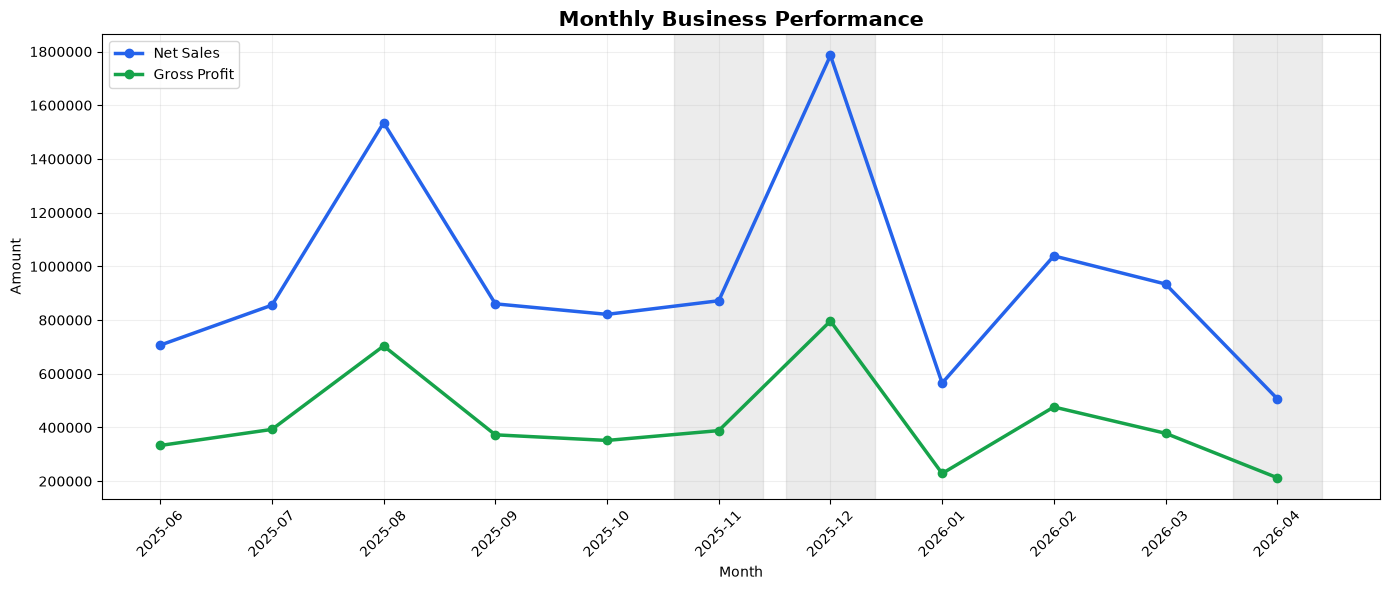

In [14]:
months = monthly_performance["Month"].astype(str)

plt.figure(figsize=(14, 6))

plt.plot(
    months,
    monthly_performance["NetSales"],
    marker="o",
    linewidth=2.5,
    color="#2563EB",
    label="Net Sales"
)

plt.plot(
    months,
    monthly_performance["GrossProfit"],
    marker="o",
    linewidth=2.5,
    color="#16A34A",
    label="Gross Profit"
)

for i, complete in enumerate(
    monthly_performance["CompleteMonth"]
):
    if not complete:
        plt.axvspan(
            i - 0.4,
            i + 0.4,
            color="gray",
            alpha=0.15
        )

plt.title(
    "Monthly Business Performance",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Amount")
plt.xticks(rotation=45)
plt.ticklabel_format(style="plain", axis="y")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

#### Product Profitability Analysis

Analyze individual product performance based on
net sales, cost of goods sold, gross profit,
sales volume and gross profit margin.

Identify profitable products, popular products
with low margins and potential opportunities
for improving business profitability.

In [15]:
product_performance = (
    business_df
    .groupby("ProductID")
    .agg(
        NetSales=("Sales", "sum"),
        COGS=("COGS", "sum"),
        GrossProfit=("GrossProfit", "sum"),
        NetUnitsSold=("QuantitySold", "sum"),
        Records=("ProductID", "size")
    )
    .reset_index()
)

product_performance["GrossMargin"] = (
    product_performance["GrossProfit"]
    / product_performance["NetSales"].where(
        product_performance["NetSales"] > 0
    ) * 100
)

product_performance = (
    product_performance
    .sort_values("GrossProfit", ascending=False)
    .reset_index(drop=True)
)

print("Products analyzed:", len(product_performance))

print("\nTop 10 products by gross profit:")

display(product_performance.head(10).round(2))

Products analyzed: 2326

Top 10 products by gross profit:


,ProductID,NetSales,COGS,GrossProfit,NetUnitsSold,Records,GrossMargin
0,PROD-140871,104027.50,46587.84,57439.66,915.0,893,55.22
1,PROD-100805,102481.99,53279.05,49202.94,1170.0,1121,48.01
2,PROD-100804,72822.50,37968.84,34853.66,834.0,838,47.86
3,PROD-100803,71496.48,37151.16,34345.32,816.0,817,48.04
4,PROD-140870,61705.00,27780.36,33924.64,546.0,565,54.98
5,PROD-140869,55251.90,24565.27,30686.63,483.0,500,55.54
6,PROD-175338,60040.00,30380.24,29659.76,316.0,46,49.40
7,PROD-100802,56361.50,29141.21,27220.29,640.0,660,48.30
8,PROD-175334,51110.00,25861.66,25248.34,269.0,59,49.40
9,PROD-152143,45672.00,23060.46,22611.54,288.0,208,49.51


#### Automated Product Opportunity Detection

Identify potential business opportunities by
comparing product sales volume, gross profit
and gross profit margins.

Use data-driven thresholds to detect popular
products with low margins, underperforming
high-margin products and loss-making products.

In [16]:
eligible_products = product_performance[
    (product_performance["NetSales"] > 0)
    & (product_performance["NetUnitsSold"] > 0)
    & (product_performance["Records"] >= 10)
].copy()

high_volume = eligible_products["NetUnitsSold"].quantile(0.75)
low_volume = eligible_products["NetUnitsSold"].quantile(0.25)

high_margin = eligible_products["GrossMargin"].quantile(0.75)
low_margin = eligible_products["GrossMargin"].quantile(0.25)

popular_low_margin = eligible_products[
    (eligible_products["NetUnitsSold"] >= high_volume)
    & (eligible_products["GrossMargin"] <= low_margin)
].sort_values("NetUnitsSold", ascending=False)

hidden_high_margin = eligible_products[
    (eligible_products["NetUnitsSold"] <= low_volume)
    & (eligible_products["GrossMargin"] >= high_margin)
].sort_values("GrossMargin", ascending=False)

loss_making_products = product_performance[
    product_performance["GrossProfit"] < 0
].sort_values("GrossProfit")

print("Popular but low-margin products:",
      len(popular_low_margin))
display(popular_low_margin.head(5).round(2))

print("\nHidden high-margin products:",
      len(hidden_high_margin))
display(hidden_high_margin.head(5).round(2))

print("\nLoss-making products:",
      len(loss_making_products))
display(loss_making_products.head(5).round(2))

Popular but low-margin products: 97


,ProductID,NetSales,COGS,GrossProfit,NetUnitsSold,Records,GrossMargin
227,PROD-100358,20189.52,15555.44,4634.08,263.0,302,22.95
301,PROD-100357,16307.04,12593.91,3713.13,213.0,223,22.77
339,PROD-100356,14499.23,11118.91,3380.32,188.0,225,23.31
669,PROD-141937,7744.63,5836.03,1908.60,138.0,145,24.64
567,PROD-159723,8401.86,6170.88,2230.98,137.0,145,26.55



Hidden high-margin products: 181


,ProductID,NetSales,COGS,GrossProfit,NetUnitsSold,Records,GrossMargin
1742,PROD-190414,400.00,120.0,280.00,10.0,10,70.00
1643,PROD-190419,484.75,147.0,337.75,14.0,14,69.68
1725,PROD-190420,414.75,126.0,288.75,12.0,12,69.62
1947,PROD-190340,275.80,84.0,191.80,10.0,10,69.54
1768,PROD-190338,383.60,117.6,266.00,14.0,14,69.34



Loss-making products: 61


,ProductID,NetSales,COGS,GrossProfit,NetUnitsSold,Records,GrossMargin
2325,PROD-145915,3825.65,4484.48,-658.83,56.0,58,-17.22
2324,PROD-179237,4131.01,4455.00,-323.99,54.0,65,-7.84
2323,PROD-139794,4504.21,4804.80,-300.59,80.0,72,-6.67
2322,PROD-145916,5625.77,5925.92,-300.15,74.0,79,-5.34
2321,PROD-159909,324.90,600.00,-275.10,12.0,13,-84.67


#### Store Performance Analysis

Analyze individual store performance based on
net sales, gross profit, gross profit margins
and average daily sales.

Identify underperforming stores and potential
opportunities for improving business performance.

In [17]:
store_performance = (
    business_df
    .groupby("Store")
    .agg(
        NetSales=("Sales", "sum"),
        COGS=("COGS", "sum"),
        GrossProfit=("GrossProfit", "sum"),
        NetUnitsSold=("QuantitySold", "sum"),
        ActiveDays=("Date", "nunique")
    )
    .reset_index()
)

store_performance["GrossMargin"] = (
    store_performance["GrossProfit"]
    / store_performance["NetSales"].where(
        store_performance["NetSales"] > 0
    ) * 100
)

store_performance["AverageDailySales"] = (
    store_performance["NetSales"]
    / store_performance["ActiveDays"]
)

store_performance["AverageDailyProfit"] = (
    store_performance["GrossProfit"]
    / store_performance["ActiveDays"]
)

store_performance = store_performance.sort_values(
    "AverageDailyProfit",
    ascending=False
).reset_index(drop=True)

print("Stores analyzed:", len(store_performance))

print("\nTop 5 performing stores:")
display(store_performance.head(5).round(2))

print("\nBottom 5 performing stores:")
display(store_performance.tail(5).round(2))

Stores analyzed: 40

Top 5 performing stores:


,Store,NetSales,COGS,GrossProfit,NetUnitsSold,ActiveDays,GrossMargin,AverageDailySales,AverageDailyProfit
0,STR-1006,485561.44,259786.30,225775.14,5619.0,323,46.50,1503.29,698.99
1,STR-1229,399696.48,222383.61,177312.87,3817.0,322,44.36,1241.29,550.66
2,STR-1080,371277.03,199581.94,171695.09,3461.0,323,46.24,1149.46,531.56
3,STR-1194,346391.53,192287.66,154103.87,4056.0,324,44.49,1069.11,475.63
4,STR-1222,329188.10,178765.33,150422.77,3200.0,322,45.70,1022.32,467.15



Bottom 5 performing stores:


,Store,NetSales,COGS,GrossProfit,NetUnitsSold,ActiveDays,GrossMargin,AverageDailySales,AverageDailyProfit
35,STR-1369,150556.35,83917.81,66638.54,1488.0,297,44.26,506.92,224.37
36,STR-1234,150442.21,84397.33,66044.88,1481.0,302,43.90,498.15,218.69
37,STR-1344,139220.10,77731.19,61488.91,1405.0,302,44.17,460.99,203.61
38,STR-1105,139447.11,78669.83,60777.28,1417.0,309,43.58,451.29,196.69
39,STR-1308,142256.04,87464.95,54791.09,2137.0,305,38.52,466.41,179.64


#### Promotion and Discount Analysis

Analyze sales performance across different pricing
and promotional strategies.

Compare net sales, gross profit, gross profit margins
and sales volume to identify potentially unprofitable
discount strategies.

In [18]:
sales_type_column = (
    "SalesType"
    if "SalesType" in business_df.columns
    else "Sales Type"
)

promotion_performance = (
    business_df
    .groupby(sales_type_column)
    .agg(
        NetSales=("Sales", "sum"),
        COGS=("COGS", "sum"),
        GrossProfit=("GrossProfit", "sum"),
        NetUnitsSold=("QuantitySold", "sum"),
        Records=("Sales", "count")
    )
    .reset_index()
)

promotion_performance["GrossMargin"] = (
    promotion_performance["GrossProfit"]
    / promotion_performance["NetSales"].where(
        promotion_performance["NetSales"] > 0
    ) * 100
)

promotion_performance["ProfitPerUnit"] = (
    promotion_performance["GrossProfit"]
    / promotion_performance["NetUnitsSold"].where(
        promotion_performance["NetUnitsSold"] > 0
    )
)

promotion_performance = (
    promotion_performance
    .sort_values("GrossMargin", ascending=False)
    .reset_index(drop=True)
)

display(promotion_performance.round(2))

,SalesType,NetSales,COGS,GrossProfit,NetUnitsSold,Records,GrossMargin,ProfitPerUnit
0,Full Price,8896456.66,4601569.87,4294886.79,87259.0,93929,48.28,49.22
1,Promo,1312929.86,962468.59,350461.27,21845.0,23651,26.69,16.04
2,Markdown Tier 1,177712.44,164961.25,12751.19,4025.0,4384,7.18,3.17
3,Markdown Tier 2,77602.53,87661.06,-10058.53,2367.0,2434,-12.96,-4.25
4,Clearance,17408.76,31090.33,-13681.57,1499.0,1353,-78.59,-9.13


#### Product Return Analysis

Analyze product return rates and returned sales value
to identify products with potential quality, sizing,
or customer satisfaction issues.

In [19]:
return_analysis = (
    business_df
    .assign(
        SoldUnits=np.where(
            business_df["IsReturn"] == 0,
            business_df["QuantitySold"], 0
        ),
        ReturnedUnits=np.where(
            business_df["IsReturn"] == 1,
            business_df["QuantitySold"].abs(), 0
        ),
        ReturnedValue=np.where(
            business_df["IsReturn"] == 1,
            business_df["Sales"].abs(), 0
        )
    )
    .groupby("ProductID")
    .agg(
        UnitsSold=("SoldUnits", "sum"),
        UnitsReturned=("ReturnedUnits", "sum"),
        ReturnValue=("ReturnedValue", "sum")
    )
    .reset_index()
)

return_analysis["ReturnRate"] = (
    return_analysis["UnitsReturned"]
    / return_analysis["UnitsSold"].where(
        return_analysis["UnitsSold"] > 0
    ) * 100
)

high_return_products = (
    return_analysis[
        (return_analysis["UnitsSold"] >= 20)
        & (return_analysis["ReturnRate"] >= 10)
    ]
    .sort_values("ReturnValue", ascending=False)
)

print("Products with high return rates:",
      len(high_return_products))

display(high_return_products.head(10).round(2))

Products with high return rates: 347


,ProductID,UnitsSold,UnitsReturned,ReturnValue,ReturnRate
1269,PROD-168539,172.0,26.0,3118.75,15.12
1268,PROD-168538,107.0,25.0,3006.25,23.36
281,PROD-140876,171.0,18.0,2120.00,10.53
1270,PROD-168540,155.0,17.0,2018.75,10.97
1263,PROD-168533,169.0,17.0,2000.00,10.06
2216,PROD-184560,72.0,9.0,1980.00,12.50
2215,PROD-184558,83.0,9.0,1980.00,10.84
8,PROD-100356,212.0,24.0,1929.79,11.32
1195,PROD-167643,101.0,17.0,1919.99,16.83
2129,PROD-181883,80.0,13.0,1852.20,16.25


#### Daily Sales Anomaly Detection

Identify unusually high or low daily sales by comparing
daily performance against historical sales patterns
for the same day of the week.

In [20]:
daily_performance = (
    business_df
    .groupby("Date")
    .agg(
        NetSales=("Sales", "sum"),
        GrossProfit=("GrossProfit", "sum")
    )
    .reset_index()
    .sort_values("Date")
)

daily_performance["DayOfWeek"] = (
    daily_performance["Date"].dt.day_name()
)

daily_performance["ExpectedSales"] = (
    daily_performance
    .groupby("DayOfWeek")["NetSales"]
    .transform(
        lambda x: x.shift(1).expanding(
            min_periods=4
        ).mean()
    )
)

daily_performance["SalesDeviation"] = (
    (
        daily_performance["NetSales"]
        - daily_performance["ExpectedSales"]
    )
    / daily_performance["ExpectedSales"].where(
        daily_performance["ExpectedSales"] > 0
    ) * 100
)

sales_anomalies = (
    daily_performance[
        daily_performance["SalesDeviation"].abs() >= 40
    ]
    .copy()
)

sales_anomalies["AnomalyType"] = np.where(
    sales_anomalies["SalesDeviation"] > 0,
    "Unusually High Sales",
    "Unusually Low Sales"
)

print("Sales anomalies detected:", len(sales_anomalies))

display(
    sales_anomalies
    .sort_values("SalesDeviation")
    .round(2)
)

Sales anomalies detected: 108


/var/folders/7d/5cs169vx0mxf0_lp0wfnbrdh0000gn/T/ipykernel_20982/716243687.py:54: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(2)


,Date,NetSales,GrossProfit,DayOfWeek,ExpectedSales,SalesDeviation,AnomalyType
236,2026-01-25,3166.13,1365.75,Sunday,29533.71,-89.28,Unusually Low Sales
237,2026-01-26,8293.03,3599.19,Monday,23221.20,-64.29,Unusually Low Sales
323,2026-04-22,10858.80,4833.67,Wednesday,28632.69,-62.08,Unusually Low Sales
225,2026-01-14,12486.98,4782.88,Wednesday,31905.39,-60.86,Unusually Low Sales
221,2026-01-10,25632.71,9707.27,Saturday,64469.76,-60.24,Unusually Low Sales
...,...,...,...,...,...,...,...
179,2025-11-28,132336.28,58635.31,Friday,35758.03,270.09,Unusually High Sales
203,2025-12-22,95155.87,42905.88,Monday,21797.15,336.55,Unusually High Sales
194,2025-12-13,266743.30,127311.51,Saturday,56765.26,369.91,Unusually High Sales
204,2025-12-23,148789.25,67402.14,Tuesday,20967.46,609.62,Unusually High Sales


#### Save Business Analysis Results

Save the calculated financial indicators, business
performance analysis, product opportunities, return
analysis and detected anomalies for integration with
the recommendation engine and dashboard.

In [21]:
analysis_dir = project_dir / "results" / "business_analysis"
analysis_dir.mkdir(parents=True, exist_ok=True)

analysis_results = {
    "business_kpis": business_kpis,
    "monthly_performance": monthly_performance,
    "product_performance": product_performance,
    "popular_low_margin": popular_low_margin,
    "hidden_high_margin": hidden_high_margin,
    "loss_making_products": loss_making_products,
    "store_performance": store_performance,
    "promotion_performance": promotion_performance,
    "return_analysis": return_analysis,
    "high_return_products": high_return_products,
    "daily_performance": daily_performance,
    "sales_anomalies": sales_anomalies
}

for name, dataframe in analysis_results.items():
    dataframe.to_csv(
        analysis_dir / f"{name}.csv",
        index=False
    )
    print(f"Saved: {name}.csv")

print("\nBusiness analysis results saved successfully.")
print("Total files:", len(analysis_results))

Saved: business_kpis.csv
Saved: monthly_performance.csv
Saved: product_performance.csv
Saved: popular_low_margin.csv
Saved: hidden_high_margin.csv
Saved: loss_making_products.csv
Saved: store_performance.csv
Saved: promotion_performance.csv
Saved: return_analysis.csv
Saved: high_return_products.csv
Saved: daily_performance.csv
Saved: sales_anomalies.csv

Business analysis results saved successfully.
Total files: 12
